# Chapter 4 figures on `ap_burst2k`

Regenerates every figure in Chapter 4 against the replacement benchmark. The figures currently
in the thesis were all produced on `data/raw/llm_generated`, where a logistic regression on a
single record's embedding scores AUROC 1.0000 -- so they illustrate a leak, not a detector.

| Thesis figure | Produced here by section | Original source |
|---|---|---|
| 4.1 Distribution of node-level anomaly scores | 2 | `all_in_one_tgn_detector.ipynb` |
| 4.2 Ground-truth vs predicted node anomalies | 2 | `all_in_one_tgn_detector.ipynb` |
| 4.3 Detection score across an injection sequence | 2 | `all_in_one_tgn_detector.ipynb` |
| 4.4 Performance vs embedding noise | 3 | `06_ood_and_noise_experiments.ipynb` |
| 4.5 Performance vs edge threshold | 3 | `06_ood_and_noise_experiments.ipynb` |
| 4.6 Metadata corruption and edge loss | 3 | `06_ood_and_noise_experiments.ipynb` |
| 4.7 Combined degradation view | 3 | `06_ood_and_noise_experiments.ipynb` |

**Three things differ from the notebooks this replaces, and each is a correction rather than a
preference.**

The sample sequence is drawn from the **test** split. The original took
`[m for m in metadata if m["label"] == "poisoned"][0]`, the first poisoned sequence in file
order, which on a shuffled split is almost always a *training* sequence. A thesis figure
showing the detector on data it was fitted to is not showing detection.

Inference runs through `MemoryTrajectoryDataset` rather than a hand-rolled snapshot-to-PyG
converter. The original notebook built `Data` objects itself and did not append the four
structural node features, which every `ap_burst2k` run is trained with. Feeding a 387-wide
tensor to a 391-wide model does not reliably raise; it silently produces wrong numbers.

The node decision threshold is **calibrated on the validation split**, not the literal `0.54`
the original hardcoded. A threshold picked by eye on the data being plotted is not a decision
rule, and 0.54 was carried over from a different benchmark entirely.

Figures are written to `experiments/eval_images_burst2k/`, which leaves the existing
`eval_images/` untouched so the thesis keeps rendering until you swap the files.

In [1]:
import json, subprocess, sys
from pathlib import Path

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from torch_geometric.data import Batch

from src.data_generation.dataset import MemoryTrajectoryDataset
from src.models.tgn_detector import TGNDetector

DATA_DIR = REPO_ROOT / "data" / "raw" / "ap_burst2k"
RUN_DIR = REPO_ROOT / "experiments" / "run_burst2k_base"
OUT_DIR = REPO_ROOT / "experiments" / "eval_images_burst2k"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Reference figures are READ from the frozen record, never typed into a cell. See
# src/experiments/freeze_reference.py for why it is a frozen snapshot and not the live
# artefacts: retraining overwrites those, which would make every check agree by construction.
REFERENCE = json.load(open(REPO_ROOT / "experiments" / "reported_results.json"))

try:
    SHA = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"],
                                  cwd=REPO_ROOT, text=True).strip()
except Exception:
    SHA = "unknown"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})

print(f"repo      : {REPO_ROOT}")
print(f"commit    : {SHA}")
print(f"device    : {device}")
print(f"reference : {len(REFERENCE['sequence_level'])} results frozen at "
      f"commit {REFERENCE.get('commit')} on {REFERENCE.get('generated')}")
print(f"output    : {OUT_DIR}")

repo      : E:\BackUp\PRJTS\msearch\impl\AI-poisoned
commit    : fa40718
device    : cuda
reference : 26 results frozen at commit 86587fb on 2026-09-22
output    : E:\BackUp\PRJTS\msearch\impl\AI-poisoned\experiments\eval_images_burst2k


## 2. Figures 4.1 to 4.3 -- node-level and single-sequence behaviour

These need no new experiment. The checkpoint, the data and the evaluation code all survive;
only the plotting lived in the superseded notebook.

In [2]:
CONFIG = yaml.safe_load(open(REPO_ROOT / "configs" / "default.yaml"))

# Every ap_burst2k run is trained with structural node features, so the model's input layer is
# four wider than the default. This must match the dataset flag below -- see train.py.
CONFIG["model"]["node_meta_dim"] = 3 + 4
T = CONFIG["training"]["temporal_window"]

CHECKPOINT = RUN_DIR / "phase2_best.pt"
assert CHECKPOINT.exists(), f"missing {CHECKPOINT}"

model = TGNDetector(CONFIG).to(device)
state = torch.load(CHECKPOINT, map_location=device, weights_only=False)
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]
model.load_state_dict(state)
model.eval()
print(f"loaded {CHECKPOINT.name}  ({sum(p.numel() for p in model.parameters()):,} parameters)")


def score_sequences(seq_ids, reset_each=False):
    '''Graph score per window and node scores from each window's final snapshot.

    Memory is reset once before the pass by default, matching how the reported figures were
    computed (see src/experiments/complementarity.tgn_scores); reset_each=True resets per
    sequence instead, which is the stricter reading of an online detector.
    '''
    ds = MemoryTrajectoryDataset(data_dir=str(DATA_DIR), split="test",
                                 temporal_window=T, sequence_ids=list(seq_ids),
                                 structural_features=True)
    rows = []
    model.reset_memory()
    with torch.no_grad():
        for i in range(len(ds)):
            item = ds[i]
            if reset_each and (i == 0 or item["sequence_id"] != rows[-1]["sequence_id"]):
                model.reset_memory()
            # The attention readout needs a batch vector, so each timestep is wrapped exactly
            # as collate_trajectories wraps it. At batch size one this is the same operation
            # the reported evaluation performs, not an approximation of it.
            graphs = [Batch.from_data_list([g]).to(device) for g in item["graphs"]]
            gs, ns = model(graphs)
            last = item["graphs"][-1]
            nl = np.asarray(last.node_labels).ravel()
            ns = ns.detach().cpu().numpy().ravel()
            m = min(len(ns), len(nl))
            rows.append({"sequence_id": item["sequence_id"],
                         "graph_score": float(np.asarray(gs.detach().cpu()).ravel()[0]),
                         "graph_label": int(item["graph_label"]),
                         "node_scores": ns[:m], "node_labels": nl[:m]})
    return rows


splits = json.load(open(DATA_DIR / "splits.json"))
meta = {m["sequence_id"]: m for m in json.load(open(DATA_DIR / "metadata.json"))}
test_poisoned = [s for s in splits["test"] if meta[s]["label"] == "poisoned"]
print(f"{len(splits['test'])} test sequences, {len(test_poisoned)} poisoned")

loaded phase2_best.pt  (670,915 parameters)
500 test sequences, 200 poisoned


In [3]:
# --- node decision threshold, calibrated on validation --------------------------------------
# The figure this replaces used a literal 0.54 with no stated provenance. A threshold has to
# come from data the figure is not drawn on, so it is fitted here on the validation split at a
# declared benign false-positive rate.
NODE_FPR = 0.05
CALIB_SEQUENCES = 60     # capped: calibration is a quantile, not an estimate needing the lot

calib_ids = splits["val"][:CALIB_SEQUENCES]
_ds = MemoryTrajectoryDataset(data_dir=str(DATA_DIR), split="val", temporal_window=T,
                              sequence_ids=calib_ids, structural_features=True)
cal_scores, cal_labels, cal_graph, cal_glabel = [], [], [], []
model.reset_memory()
with torch.no_grad():
    for i in range(len(_ds)):
        item = _ds[i]
        gs, ns = model([Batch.from_data_list([g]).to(device) for g in item["graphs"]])
        nl = np.asarray(item["graphs"][-1].node_labels).ravel()
        ns = ns.detach().cpu().numpy().ravel()
        m = min(len(ns), len(nl))
        cal_scores.append(ns[:m]); cal_labels.append(nl[:m])
        cal_graph.append(float(np.asarray(gs.detach().cpu()).ravel()[0]))
        cal_glabel.append(int(item["graph_label"]))

cal_scores = np.concatenate(cal_scores); cal_labels = np.concatenate(cal_labels)
cal_graph = np.array(cal_graph); cal_glabel = np.array(cal_glabel)

# Two separate thresholds, because they live on two different score scales. Figures 4.1 and
# 4.2 mark nodes; figure 4.3 marks windows. Drawing one on the other's axis is meaningless,
# which is exactly what the first draft of this notebook did.
benign_nodes = cal_scores[cal_labels == 0]
NODE_THRESHOLD = float(np.quantile(benign_nodes, 1.0 - NODE_FPR))
benign_windows = cal_graph[cal_glabel == 0]
GRAPH_THRESHOLD = float(np.quantile(benign_windows, 1.0 - NODE_FPR))

print(f"calibrated on {len(calib_ids)} validation sequences")
print(f"  nodes  : {len(benign_nodes):,} benign, "
      f"{int((cal_labels == 1).sum()):,} poisoned")
print(f"  windows: {int((cal_glabel == 0).sum()):,} benign, "
      f"{int((cal_glabel == 1).sum()):,} poisoned")
print(f"node threshold  at {NODE_FPR:.0%} benign FPR : {NODE_THRESHOLD:.4f}")
print(f"graph threshold at {NODE_FPR:.0%} benign FPR : {GRAPH_THRESHOLD:.4f}")

calibrated on 60 validation sequences
  nodes  : 96,808 benign, 2,192 poisoned
  windows: 498 benign, 162 poisoned
node threshold  at 5% benign FPR : 0.3767
graph threshold at 5% benign FPR : 0.9784


In [4]:
# --- pick the sequence the single-sequence figures are drawn on ------------------------------
# Test split only, and two conditions rather than one.
#
# Attack size near the test median, so the figure shows a typical attack and not the easiest.
#
# Onset late enough that pre-onset windows exist. `_place` starts a burst anywhere from
# interaction 40 onward, so on many sequences the injection is already present in the first
# evaluable window (which ends at snapshot T-1 = 9). Every window is then positive, the trace
# is flat at 1.0, and the figure shows nothing about onset. Requiring onset >= T+2 leaves at
# least three clean windows before the rise; capping it leaves at least three after.
def onset_snapshot(seq_id):
    '''Index of the first snapshot whose graph label is positive.'''
    for i, p in enumerate(sorted((DATA_DIR / seq_id).glob("snapshot_*.npz"))):
        with np.load(p) as z:
            if int(np.asarray(z["graph_label"]).ravel()[0]) == 1:
                return i
    return None


sizes = np.array([meta[s]["num_injected"] for s in test_poisoned])
median_size = float(np.median(sizes))
by_typicality = [test_poisoned[i] for i in np.argsort(np.abs(sizes - median_size))]

SEQ_ID, ONSET = None, None
for cand in by_typicality[:80]:
    o = onset_snapshot(cand)
    if o is not None and T + 2 <= o <= 16:
        SEQ_ID, ONSET = cand, o
        break
if SEQ_ID is None:                     # no sequence met both conditions; fall back to typical
    SEQ_ID = by_typicality[0]
    ONSET = onset_snapshot(SEQ_ID)
    print("WARNING: no candidate had a late enough onset; the trace may be flat.")

rows = score_sequences([SEQ_ID])
graph_scores = np.array([r["graph_score"] for r in rows])
graph_truth = np.array([r["graph_label"] for r in rows])
node_scores, node_labels = rows[-1]["node_scores"], rows[-1]["node_labels"]

print(f"sequence        : {SEQ_ID}")
print(f"attack type     : {meta[SEQ_ID]['attack_type']}")
print(f"injected records: {meta[SEQ_ID]['num_injected']}  (test median {median_size:.0f})")
print(f"onset snapshot  : {ONSET}")
print(f"windows         : {len(rows)}  "
      f"({int((graph_truth == 0).sum())} pre-onset, {int((graph_truth == 1).sum())} after)")
print(f"final window    : {len(node_labels)} nodes, {int(node_labels.sum())} poisoned")

sequence        : poisoned_placement_0463
attack type     : flood_placement
injected records: 12  (test median 12)
onset snapshot  : 16
windows         : 11  (7 pre-onset, 4 after)
final window    : 200 nodes, 12 poisoned


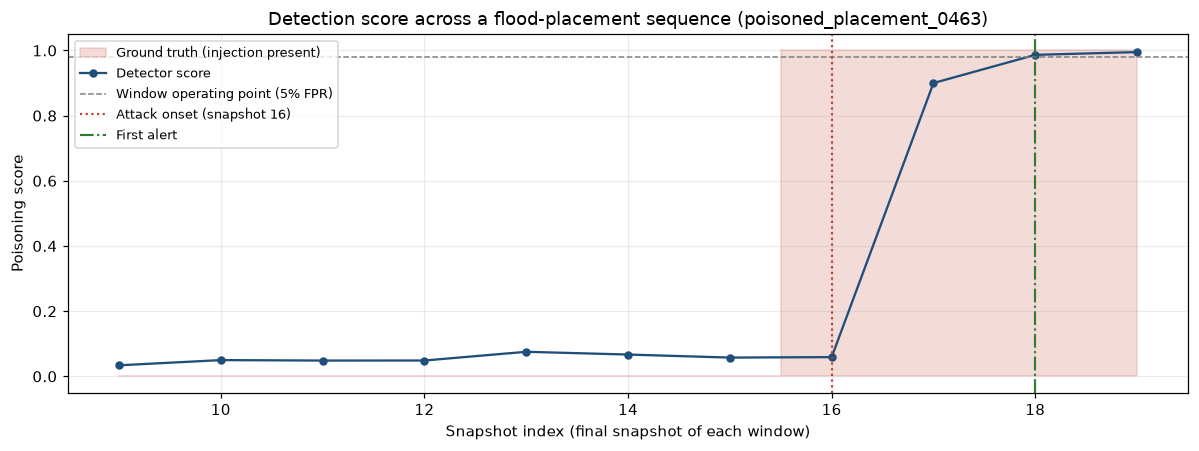

test-wide detection latency: mean 1.85, median 1.0 windows
Read this figure as one illustrative trace, not as evidence of the latency claim --
the latency figure above is the measurement that carries that claim.


In [5]:
# ============================== FIGURE 4.3 ==================================================
# Detection score across the lifetime of one poisoned sequence.
fig, ax = plt.subplots(figsize=(11, 4.2))
steps = np.arange(T - 1, T - 1 + len(graph_scores))

ax.fill_between(steps, 0, graph_truth, alpha=0.18, color="#c0392b", step="mid",
                label="Ground truth (injection present)")
ax.plot(steps, graph_scores, "-o", color="#1f4e79", markersize=4.5, label="Detector score")
ax.axhline(GRAPH_THRESHOLD, color="gray", ls="--", lw=1,
           label=f"Window operating point ({NODE_FPR:.0%} FPR)")

first_pos = np.flatnonzero(graph_truth == 1)
if first_pos.size:
    ax.axvline(steps[first_pos[0]], color="#c0392b", ls=":", lw=1.4,
               label=f"Attack onset (snapshot {ONSET})")
fired = np.flatnonzero(graph_scores > GRAPH_THRESHOLD)
if fired.size:
    ax.axvline(steps[fired[0]], color="#2e7d32", ls="-.", lw=1.4, label="First alert")

ax.set_xlabel("Snapshot index (final snapshot of each window)")
ax.set_ylabel("Poisoning score")
ax.set_title(f"Detection score across a flood-placement sequence ({SEQ_ID})")
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_4_3_single_sequence_detection_score.png", bbox_inches="tight")
plt.show()

lat = REFERENCE["window_level"]["detection_latency"]
print(f"test-wide detection latency: mean {lat['mean_detection_latency']:.2f}, "
      f"median {lat['median_detection_latency']:.1f} windows")
print("Read this figure as one illustrative trace, not as evidence of the latency claim --")
print("the latency figure above is the measurement that carries that claim.")

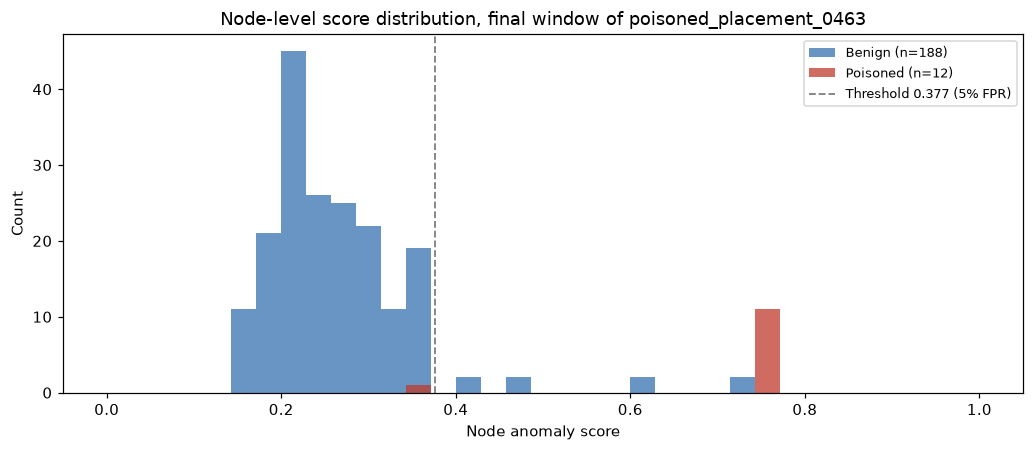

test-wide node AUROC 0.9087, node AP 0.5662
The histogram is one sequence; those two numbers are the whole test partition and are
what Chapter 4 should quote. Check the single sequence looks representative of them.


In [6]:
# ============================== FIGURE 4.1 ==================================================
# Node-level score distribution, benign against poisoned, in the final window.
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bn = node_scores[node_labels == 0]
pz = node_scores[node_labels == 1]
bins = np.linspace(0, 1, 36)

ax.hist(bn, bins=bins, alpha=0.75, color="#3572b0", label=f"Benign (n={len(bn)})")
ax.hist(pz, bins=bins, alpha=0.75, color="#c0392b", label=f"Poisoned (n={len(pz)})")
ax.axvline(NODE_THRESHOLD, color="gray", ls="--", lw=1.2,
           label=f"Threshold {NODE_THRESHOLD:.3f} ({NODE_FPR:.0%} FPR)")
ax.set_xlabel("Node anomaly score")
ax.set_ylabel("Count")
ax.set_title(f"Node-level score distribution, final window of {SEQ_ID}")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_4_1_node_score_distribution.png", bbox_inches="tight")
plt.show()

nl = REFERENCE["window_level"]["node"]
print(f"test-wide node AUROC {nl['node_auroc']:.4f}, node AP "
      f"{nl['node_average_precision']:.4f}")
print("The histogram is one sequence; those two numbers are the whole test partition and are")
print("what Chapter 4 should quote. Check the single sequence looks representative of them.")

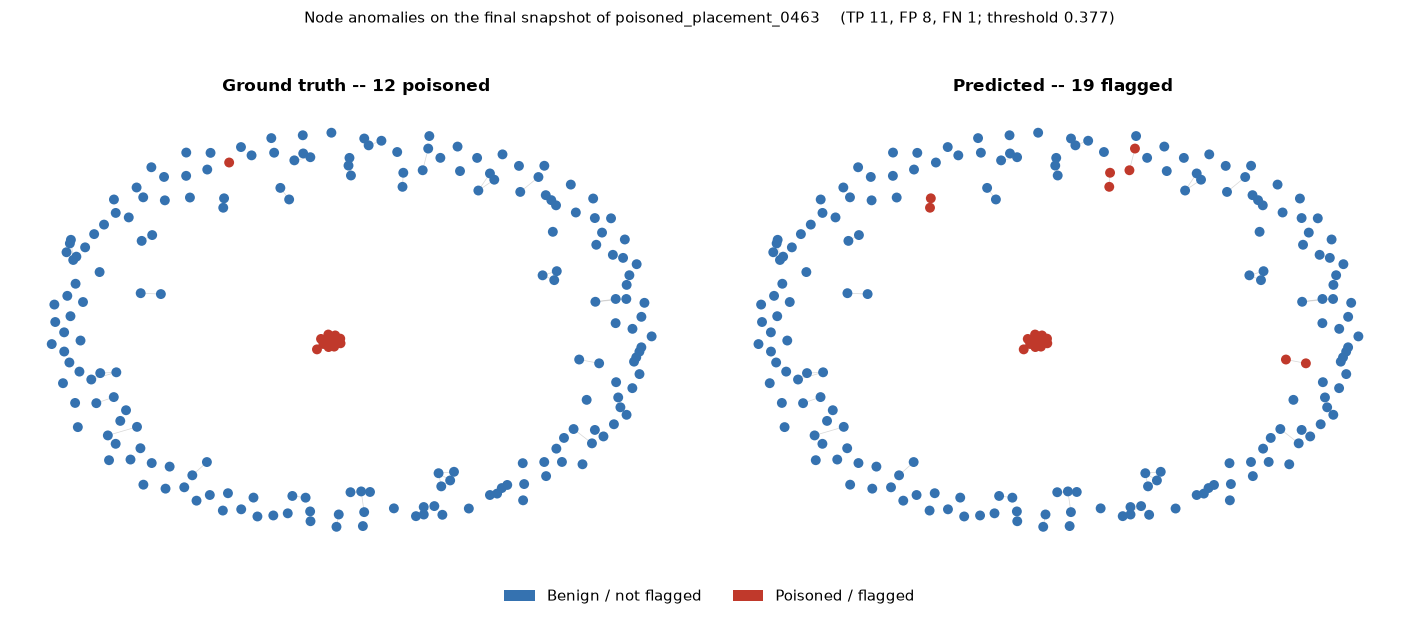

In [7]:
# ============================== FIGURE 4.2 ==================================================
# Ground truth against predicted node anomalies on the final snapshot.
try:
    import networkx as nx
except ImportError:
    nx = None
    print("networkx not installed -- skipping figure 4.2 (pip install networkx)")

if nx is not None:
    last = rows[-1]
    _ds = MemoryTrajectoryDataset(data_dir=str(DATA_DIR), split="test", temporal_window=T,
                                  sequence_ids=[SEQ_ID], structural_features=True)
    g = _ds[len(_ds) - 1]["graphs"][-1]
    ei = np.asarray(g.edge_index)

    G = nx.Graph()
    G.add_nodes_from(range(len(node_labels)))
    if ei.size:
        G.add_edges_from({(int(a), int(b)) for a, b in zip(ei[0], ei[1]) if a != b})

    pos = nx.spring_layout(G, seed=42, k=2.0 / np.sqrt(max(1, G.number_of_nodes())))
    pred = node_scores > NODE_THRESHOLD

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
    for ax, colour_by, title in (
            (axes[0], node_labels == 1, f"Ground truth -- {int(node_labels.sum())} poisoned"),
            (axes[1], pred, f"Predicted -- {int(pred.sum())} flagged")):
        cols = ["#c0392b" if colour_by[n] else "#3572b0" for n in G.nodes]
        nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15, width=0.5)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cols, node_size=42, linewidths=0)
        ax.set_title(title, fontweight="bold", fontsize=11)
        ax.axis("off")

    tp = int((pred & (node_labels == 1)).sum()); fp = int((pred & (node_labels == 0)).sum())
    fn = int((~pred & (node_labels == 1)).sum())
    fig.suptitle(f"Node anomalies on the final snapshot of {SEQ_ID}    "
                 f"(TP {tp}, FP {fp}, FN {fn}; threshold {NODE_THRESHOLD:.3f})", fontsize=10)
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(facecolor="#3572b0", label="Benign / not flagged"),
                        Patch(facecolor="#c0392b", label="Poisoned / flagged")],
               loc="lower center", ncol=2, frameon=False)
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.savefig(OUT_DIR / "fig_4_2_node_graph_overlay.png", bbox_inches="tight")
    plt.show()

## 3. Figures 4.4 to 4.7 -- robustness under input degradation

These **do** need a new experiment. The four sweeps were never run on `ap_burst2k`, so unlike
section 2 there is no stored result to plot; `RUN_OOD` has to be True at least once.

`ood_evaluator.py` gained a `--structural-features` flag for this. Without it the evaluator
builds a `node_meta_dim=3` model and loads a `node_meta_dim=7` checkpoint into it. That is the
mismatch that produced `eval_ap_scale.INVALID_train_eval_mismatch.json`, which is kept in the
repository precisely because it did not announce itself.

Three caveats to carry into Section 4.9.

Each condition is evaluated under a **single** draw of the perturbation, with no repetition,
so the curves carry no estimate of the variability the perturbation itself induces. Read where
a curve turns as approximate, not as a located threshold. That limitation is in the existing
Section 3.11 text and still applies.

The sweep evaluates a **random sample** of test windows, not the whole partition, because
preloading all 5,500 to VRAM needs far more memory than the 4 GB card this project reports
timings on. The sample is seeded and drawn across the whole split. It previously took the
first N windows in dataset order, which meant roughly nine sequences out of five hundred
selected by file order, and scored about 0.05 above the full partition.

Inference on GPU is **not bitwise reproducible**. Two identical passes over the same windows
differ by up to about 3e-07 per score, because the scatter operations underlying attention
pooling sum in nondeterministic order. AUROC is a rank statistic, so that flips near-tied
pairs and moves the fourth decimal: the three zero-perturbation conditions here agree to
about 0.0006 rather than exactly. Treat differences below roughly 0.002 between conditions as
noise, and the 0.02 figure used elsewhere in this project as the threshold for a finding.

In [8]:
RUN_OOD = False          # True runs the four sweeps (~20-40 min on GPU, longer on CPU)
OOD_MAX_SAMPLES = 150    # test windows per condition; raise for tighter curves, at linear cost

OOD_JSON = RUN_DIR / "ood_results_burst2k.json"
OOD_CMD = [sys.executable, "-m", "src.experiments.ood_evaluator",
           "--data", "data/raw/ap_burst2k",
           "--checkpoint", str(CHECKPOINT.relative_to(REPO_ROOT)).replace("\\", "/"),
           "--output", str(OOD_JSON.relative_to(REPO_ROOT)).replace("\\", "/"),
           "--max-samples", str(OOD_MAX_SAMPLES),
           "--structural-features"]

if RUN_OOD:
    print(" ".join(OOD_CMD))
    subprocess.run(OOD_CMD, cwd=REPO_ROOT, check=True)

if OOD_JSON.exists():
    ood = json.load(open(OOD_JSON))
    clean = ood["baseline_clean"]
    print(f"clean baseline: graph AUROC {clean['graph_auroc']:.4f}, "
          f"AP {clean['graph_ap']:.4f}, node AUROC {clean['node_auroc']:.4f}")
    ref = REFERENCE["window_level"]["graph"]["auroc"]
    print(f"reference (window-level graph AUROC, full test split): {ref:.4f}")
    print("These two differ legitimately: the sweep evaluates a capped sample of windows.")
    print("A large gap means OOD_MAX_SAMPLES is too small, not that the detector moved.")
else:
    ood = None
    print(f"not found: {OOD_JSON}")
    print("Set RUN_OOD = True and re-run this cell. Figures 4.4-4.7 cannot be drawn without it.")

clean baseline: graph AUROC 0.8269, AP 0.7782, node AUROC 0.9006
reference (window-level graph AUROC, full test split): 0.8261
These two differ legitimately: the sweep evaluates a capped sample of windows.
A large gap means OOD_MAX_SAMPLES is too small, not that the detector moved.


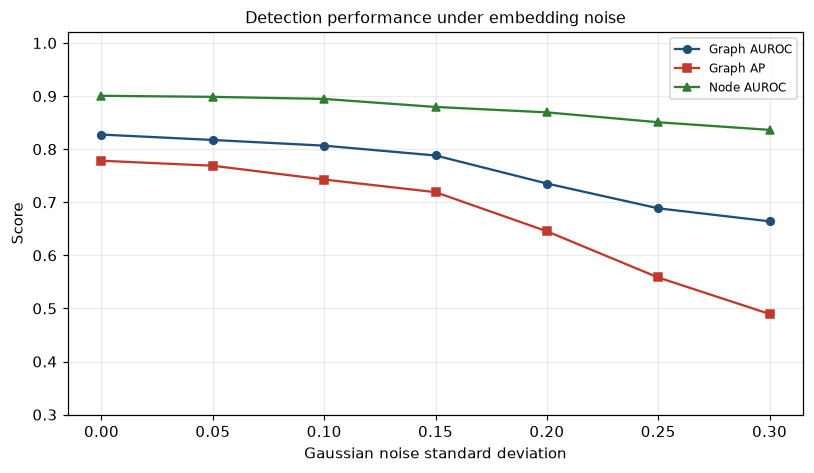

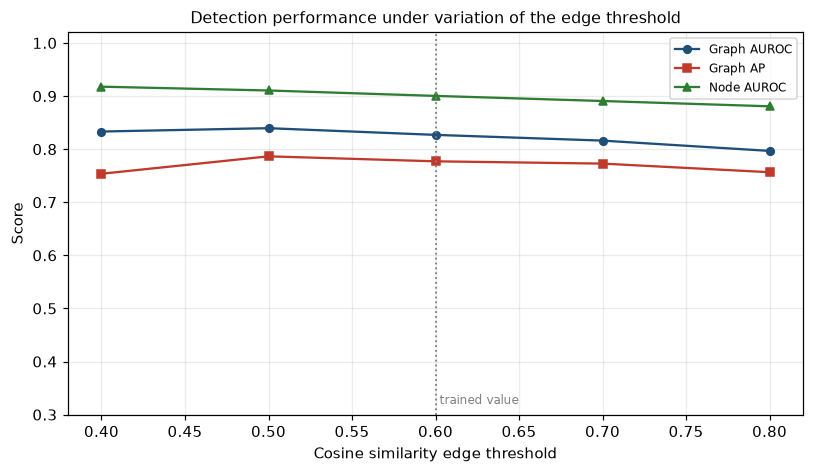

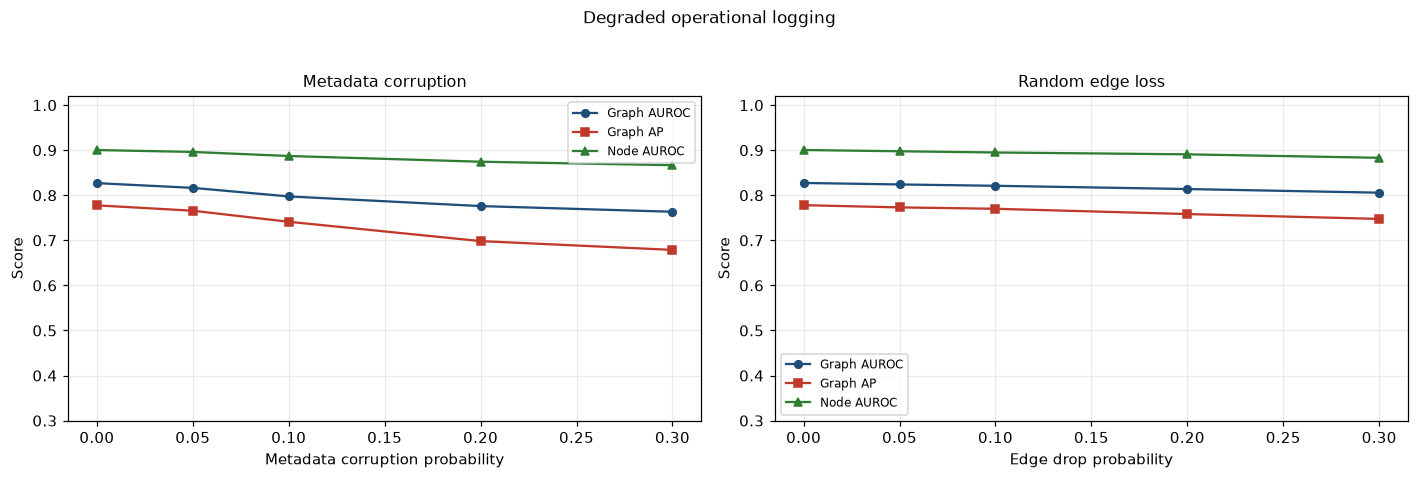

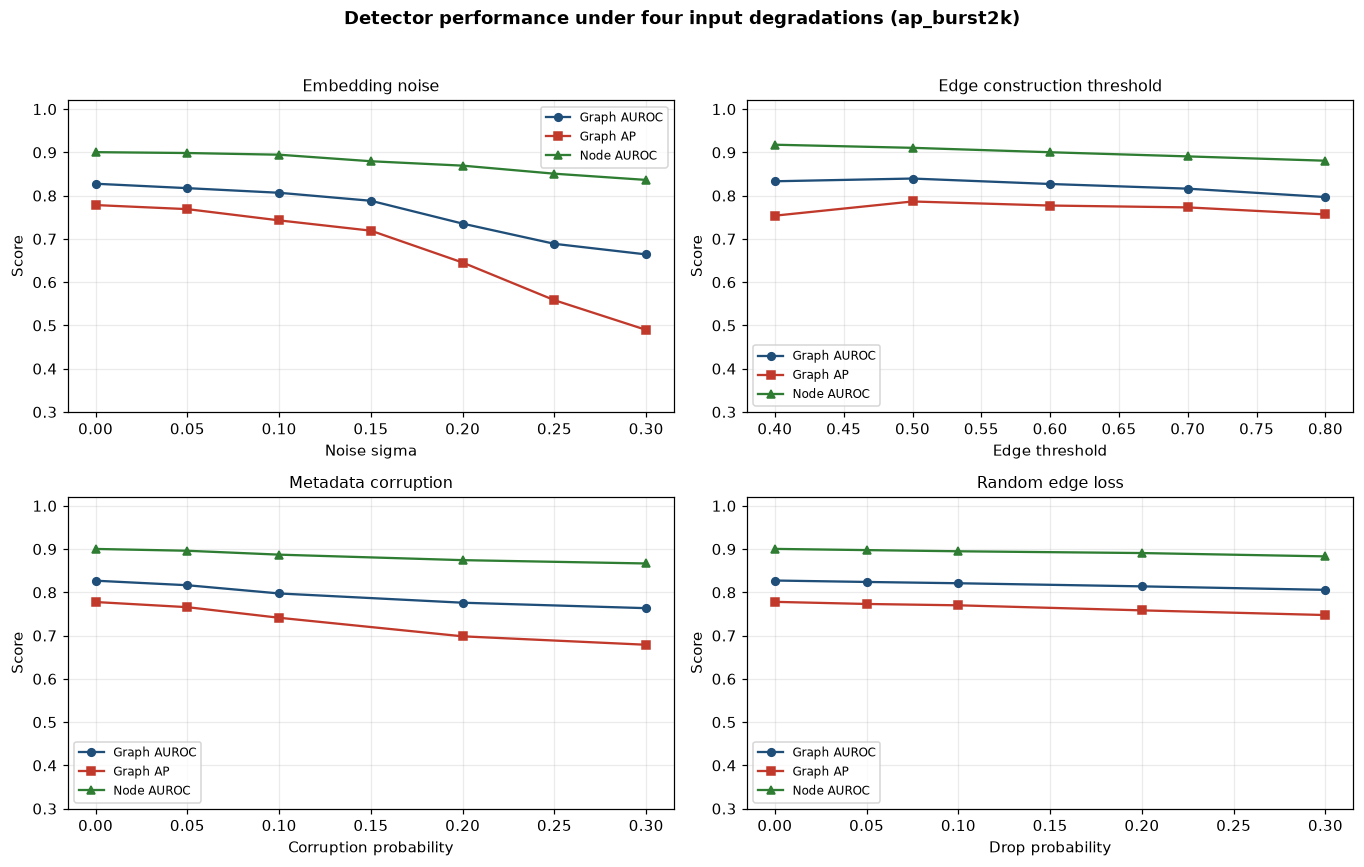

In [9]:
def sweep_xy(block, metric):
    xs = sorted(float(k) for k in block)
    return np.array(xs), np.array([block[str(k) if str(k) in block else repr(k)][metric]
                                   for k in xs])


def draw_sweep(ax, block, xlabel, title):
    for metric, label, colour, mark in (("graph_auroc", "Graph AUROC", "#1f4e79", "o"),
                                        ("graph_ap", "Graph AP", "#c0392b", "s"),
                                        ("node_auroc", "Node AUROC", "#2e7d32", "^")):
        x, y = sweep_xy(block, metric)
        ax.plot(x, y, marker=mark, color=colour, label=label, markersize=5)
    ax.set_xlabel(xlabel); ax.set_ylabel("Score")
    ax.set_title(title, fontsize=10.5)
    ax.set_ylim(0.3, 1.02); ax.grid(alpha=0.25); ax.legend(fontsize=8)


if ood:
    # ---------------------------- FIGURE 4.4 ------------------------------------------------
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    draw_sweep(ax, ood["embedding_noise_sweep"], "Gaussian noise standard deviation",
               "Detection performance under embedding noise")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "fig_4_4_embedding_noise.png", bbox_inches="tight")
    plt.show()

    # ---------------------------- FIGURE 4.5 ------------------------------------------------
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    draw_sweep(ax, ood["threshold_sensitivity_sweep"], "Cosine similarity edge threshold",
               "Detection performance under variation of the edge threshold")
    ax.axvline(CONFIG["simulation"]["semantic_edge_threshold"], color="gray", ls=":", lw=1.2)
    ax.text(CONFIG["simulation"]["semantic_edge_threshold"], 0.32, " trained value",
            fontsize=8, color="gray")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "fig_4_5_edge_threshold.png", bbox_inches="tight")
    plt.show()

    # ---------------------------- FIGURE 4.6 ------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    draw_sweep(axes[0], ood["metadata_corruption_sweep"], "Metadata corruption probability",
               "Metadata corruption")
    draw_sweep(axes[1], ood["edge_loss_sweep"], "Edge drop probability", "Random edge loss")
    fig.suptitle("Degraded operational logging", fontsize=11)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(OUT_DIR / "fig_4_6_metadata_and_edge_loss.png", bbox_inches="tight")
    plt.show()

    # ---------------------------- FIGURE 4.7 ------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
    for ax, (key, xlabel, title) in zip(axes.ravel(), (
            ("embedding_noise_sweep", "Noise sigma", "Embedding noise"),
            ("threshold_sensitivity_sweep", "Edge threshold", "Edge construction threshold"),
            ("metadata_corruption_sweep", "Corruption probability", "Metadata corruption"),
            ("edge_loss_sweep", "Drop probability", "Random edge loss"))):
        draw_sweep(ax, ood[key], xlabel, title)
    fig.suptitle("Detector performance under four input degradations (ap_burst2k)",
                 fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(OUT_DIR / "fig_4_7_degradation_dashboard.png", bbox_inches="tight")
    plt.show()
else:
    print("No OOD results -- set RUN_OOD = True in the cell above.")

In [10]:
# --- what was produced ----------------------------------------------------------------------
produced = sorted(OUT_DIR.glob("fig_4_*.png"))
expected = {"fig_4_1_node_score_distribution.png": "4.1",
            "fig_4_2_node_graph_overlay.png": "4.2",
            "fig_4_3_single_sequence_detection_score.png": "4.3",
            "fig_4_4_embedding_noise.png": "4.4",
            "fig_4_5_edge_threshold.png": "4.5",
            "fig_4_6_metadata_and_edge_loss.png": "4.6",
            "fig_4_7_degradation_dashboard.png": "4.7"}
print(f"{OUT_DIR}\n")
for name, fig_no in expected.items():
    p = OUT_DIR / name
    state = f"{p.stat().st_size / 1024:>7.0f} KB" if p.exists() else "   MISSING"
    print(f"  Figure {fig_no}  {state}  {name}")
missing = [f for f, n in expected.items() if not (OUT_DIR / f).exists()]
print(f"\n{len(expected) - len(missing)} of {len(expected)} produced")
if missing:
    print("Missing figures are the ones whose cell did not run or whose experiment was skipped.")

E:\BackUp\PRJTS\msearch\impl\AI-poisoned\experiments\eval_images_burst2k

  Figure 4.1       81 KB  fig_4_1_node_score_distribution.png
  Figure 4.2      304 KB  fig_4_2_node_graph_overlay.png
  Figure 4.3      145 KB  fig_4_3_single_sequence_detection_score.png
  Figure 4.4      128 KB  fig_4_4_embedding_noise.png
  Figure 4.5      115 KB  fig_4_5_edge_threshold.png
  Figure 4.6      181 KB  fig_4_6_metadata_and_edge_loss.png
  Figure 4.7      373 KB  fig_4_7_degradation_dashboard.png

7 of 7 produced


## 4. Using these in the thesis

Replace the file behind each figure, keeping the numbering. Three captions need wording
changes beyond the numbers:

**4.3** currently reads *"across a query-level injection sequence"*. `ap_burst2k` has one
attack type, `flood_placement`, so that phrase has no referent -- say *"across a
flood-placement injection sequence"*.

**4.1 and 4.2** are drawn on one test sequence, as before, but the sequence is now chosen by
median attack size rather than file order. If the caption claims anything about typicality it
can now be defended; previously it could not.

**4.4 to 4.7** must not be presented as comparable to the figures they replace. The originals
sat on a benchmark where clean graph AUROC was 1.0000, so every curve started at the ceiling
and could only fall. Starting from a real operating point, a flat curve means something
different than it did before, and a Section 4.9 rewritten around these needs to say so.